In [ ]:
'''
figure out more versions of SNR: whole image and chunked
(including for stars we don't have good matches for)
'''

In [101]:
import pandas as pd
import numpy as np
import review_findings_functions as rff
import importlib
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/home/3155/inference_star_info_r12_bands")

In [12]:
df['star_ra'].isnull().values.any()

True

In [15]:
np.sum(df['star_ra'].isnull())

156

In [88]:
def add_snr_whole_and_chunks_test(df, half_aperture=2, tracking=True):
    """
    returns the dataframe with new columns for snr, stdv, and average value
    for both whole time series and chunks of it
    """
    snr_whole = np.zeros(len(df))
    snr_chunks = np.zeros(len(df))
    stdv_whole = np.zeros(len(df))
    stdv_chunks = np.zeros(len(df))
    avg_whole = np.zeros(len(df))
    avg_chunks = np.zeros(len(df))
    for index in tqdm(df.index[:100]):
        # print(index)
        tot, maxcols =rff. get_tot(df, index, half_aperture, tracking)
        ratio, stdv, avg = rff.get_snr_whole_image(tot, df, index)
        ratio_ch, stdv_ch, avg_ch = rff.get_snr_chunks(tot, df, index)
        snr_whole[index] = ratio
        snr_chunks[index] = ratio_ch
        stdv_whole[index] = stdv
        stdv_chunks[index] = stdv_ch
        avg_whole[index] = avg
        avg_chunks[index] = avg_ch
    df["snr_whole"] = snr_whole
    df["snr_chunks"] = snr_chunks
    df["stdv_whole"] = stdv_whole
    df["stdv_chunks"] = stdv_chunks
    df["avg_whole"] = avg_whole
    df["avg_chunks"] = avg_chunks
    return df

In [89]:
df_plus_snr = add_snr_whole_and_chunks_tes(df)

  0%|          | 0/100 [00:00<?, ?it/s]

In [94]:
df_plus_snr.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', '0', '1', '2', '3', '4', 'filename',
       'type', 'row_from_nn', 'col_from_nn', 'detection_size', 'quadrant',
       'sobel_ratio', 'snr_center', 'snr_max', 'snr_min', 'closest_x',
       'closest_y', 'Diff', 'star_ra', 'star_dec', 'Band', 'gaia_source_id',
       'g_mag', 'bp_rp', 'rp_mag_ztf_ri', 'bp_mag_ztf_g', 'variability',
       'in_vari_summary', 'snr_whole', 'snr_chunks', 'stdv_whole',
       'stdv_chunks', 'avg_whole', 'avg_chunks'],
      dtype='object')

In [128]:
df_plus_snr = pd.read_csv("/home/3155/df_plus_snr")

FileNotFoundError: [Errno 2] No such file or directory: '/home/3155/df_plus_snr'

In [ ]:
plt.hist(df_plus_snr['snr_whole'])
plt.title("Snr of whole time series in one image")
plt.ylabel('counts')
plt.xlabel('SNR')

In [ ]:
plt.hist(df_plus_snr['snr_chunks'])
plt.title("Snr of chunked time series in one image")
plt.ylabel('counts')
plt.xlabel('SNR')

In [ ]:
#also want to make number of candidates per star
#one with snr limit and one not, probably
#but easy enough to swap df going into it

In [111]:
name, counts = np.unique(df['gaia_source_id'], return_counts=True)

In [112]:
len(name)

897

Text(0, 0.5, 'Number of sources (stars)')

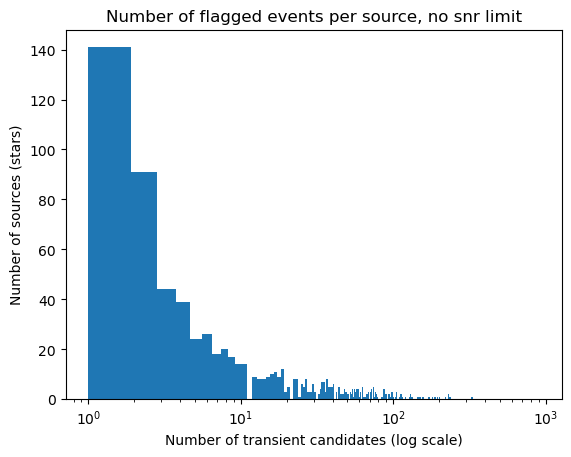

In [125]:
plt.hist(counts,bins=1000)
plt.title("Number of flagged events per source, no snr limit")
# plt.xlim(0,500)
plt.xscale("log")
plt.xlabel("Number of transient candidates (log scale)")
plt.ylabel("Number of sources (stars)")

Text(0, 0.5, 'Number of sources (stars)')

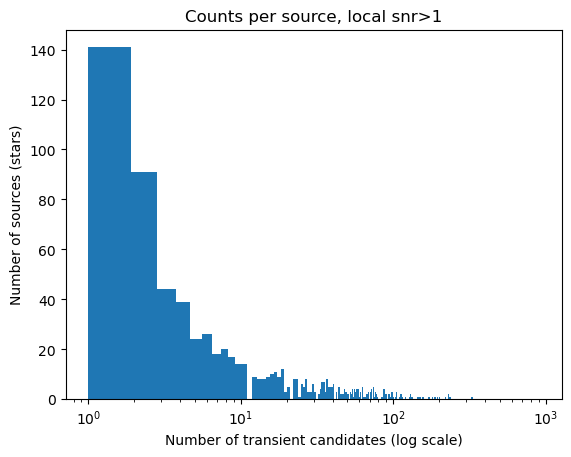

In [130]:
df_snr_limited = df[np.abs(df['snr_center'])>1]
name, counts = np.unique(df_snr_limited['gaia_source_id'], return_counts=True)
plt.hist(counts,bins=1000)
plt.title("Counts per source, local snr>1")
# plt.xlim(0,500)
plt.xscale("log")
plt.xlabel("Number of transient candidates (log scale)")
plt.ylabel("Number of sources (stars)")

Text(0, 0.5, 'Number of sources (stars)')

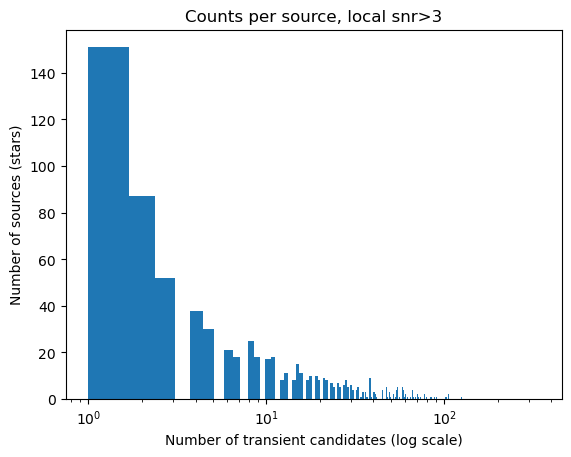

In [129]:
df_snr_limited = df[np.abs(df['snr_center'])>3]
name, counts = np.unique(df_snr_limited['gaia_source_id'], return_counts=True)
plt.hist(counts,bins=500)
plt.title("Counts per source, local snr>3")
# plt.xlim(0,500)
plt.xscale("log")
plt.xlabel("Number of transient candidates (log scale)")
plt.ylabel("Number of sources (stars)")